In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [26]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [27]:
strings = ['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']
data = df[strings]
data.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [28]:
data.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [29]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


In [30]:
data.describe()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


In [31]:
skew = data['fuel_efficiency_mpg'].skew()
print(f"Skew: {skew:.3f} -> {'long tail' if abs(skew) > 0.5 else 'roughly symmetric'}")


Skew: 0.081 -> roughly symmetric


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

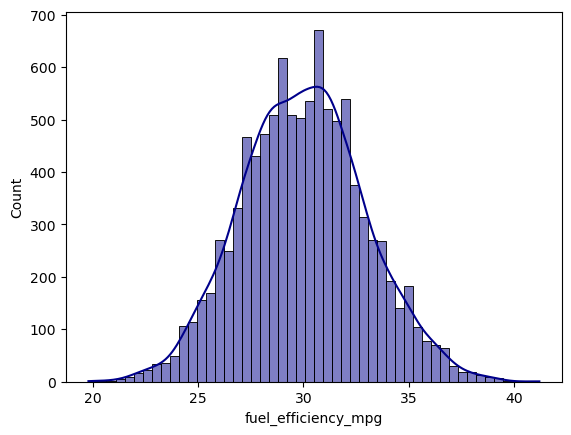

In [32]:
sns.histplot(data["fuel_efficiency_mpg"], color = "darkblue", bins = 50, kde = True)

## note, distribution of fuel_efficiency_mpg  does not have a tail, it follows a normal distribution

In [33]:
data["horsepower"].median()

254.0

In [34]:
def linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XT = X.T
    XTX = XT.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(XT.dot(y))
    return w[0], w[1:]

def linear_regression_reg(X, y, r = 0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XT = X.T
    XTX = XT.dot(X)
    XTX = XTX + r*np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(XT.dot(y))
    return w[0], w[1:]

def prepare_X(df_, column_name, fillna_value):
    df_num = df_.copy()
    df_num[column_name] = df_num[column_name].fillna(fillna_value)
    return df_num

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

def split_data(df_, seed):
    n = len(df_)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df_.iloc[idx[:n_train]]
    df_val = df_.iloc[idx[n_train:n_train + n_val]]
    df_test = df_.iloc[idx[n_train+n_val:]]
    
    print(f"df_train shape: {df_train.shape}")
    print(f"df_val shape: {df_val.shape}")
    print(f"df_test shape: {df_test.shape}")

    return df_train, df_val, df_test
    

In [35]:
df_train, df_val, df_test = split_data(data, seed = 42)
y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values

#option A, filling all missing values with 0
# horsepower 

X_train_0 = prepare_X(df_train, "horsepower", 0)

print("X_tain head")
print(X_train_0.head())
print(X_train_0.isna().sum())

X_val_0 = prepare_X(df_val, "horsepower", 0)

print("X_val head")
print(X_val_0.head())
print(X_val_0.isna().sum())



df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
X_tain head
      engine_displacement  horsepower  vehicle_weight  model_year  \
6252                 1900       239.0            3790        2015   
4684                 2000       224.0            4380        1992   
1731                 2330       286.0            4090        2022   
4742                 2300         0.0            4150        1997   
4521                 2340       269.0            4400        2001   

      fuel_efficiency_mpg  
6252                 32.5  
4684                 29.1  
1731                 34.1  
4742                 30.6  
4521                 30.7  
engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
fuel_efficiency_mpg    0
dtype: int64
X_val head
      engine_displacement  horsepower  vehicle_weight  model_year  \
2480                 2240       265.0            3990        2004   
289                  2390       259.0      

## **linear regression without regularization**

#### missing values filled with 0

In [36]:
w0, w = linear_regression(X_train_0.drop(columns = "fuel_efficiency_mpg"), y_train)
print(w0, w)
y_pred_0 = w0 + X_val_0.drop(columns = "fuel_efficiency_mpg").dot(w)
rmse_0 = round(rmse(y_pred_0, y_val), 3)
print("RMSE (fill with 0):", rmse_0)


-153.88496188313275 [-1.51505520e-03 -4.74024797e-06 -3.95418397e-03  1.02146785e-01]
RMSE (fill with 0): 2.205


#### missing values filled with the mean

In [37]:
#option B, filling all missing values with mean of train['horsepower'] 

X_train_mean = prepare_X(df_train, "horsepower", df["horsepower"].mean())

print("X_tain_mean head")
print(X_train_mean.head())
print(X_train_mean.isna().sum())

X_val_mean = prepare_X(df_val, "horsepower", df["horsepower"].mean())

print("X_val head")
print(X_val_0.head())
print(X_val_0.isna().sum())



X_tain_mean head
      engine_displacement  horsepower  vehicle_weight  model_year  \
6252                 1900  239.000000            3790        2015   
4684                 2000  224.000000            4380        1992   
1731                 2330  286.000000            4090        2022   
4742                 2300  254.446016            4150        1997   
4521                 2340  269.000000            4400        2001   

      fuel_efficiency_mpg  
6252                 32.5  
4684                 29.1  
1731                 34.1  
4742                 30.6  
4521                 30.7  
engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
fuel_efficiency_mpg    0
dtype: int64
X_val head
      engine_displacement  horsepower  vehicle_weight  model_year  \
2480                 2240       265.0            3990        2004   
289                  2390       259.0            4770        2019   
6086                 2360       265.0       

In [38]:
w0, w = linear_regression(X_train_mean.drop(columns = "fuel_efficiency_mpg"), y_train)
y_pred_mean = w0 + X_val_mean.drop(columns = "fuel_efficiency_mpg").dot(w)
rmse_mean = round(rmse(y_pred_mean, y_val), 3)
print("RMSE (fill with 0):", rmse_0)

RMSE (fill with 0): 2.205


In [39]:
if rmse_0 < rmse_mean:
    print("rmse_0 is better")
else:
    print("rmse_mean is better")

rmse_mean is better


In [40]:
print("Better option:", "With 0" 
      if rmse_0 < rmse_mean 
      else ("With mean" if rmse_mean < rmse_0 else "Both are equally good"))


Better option: With mean


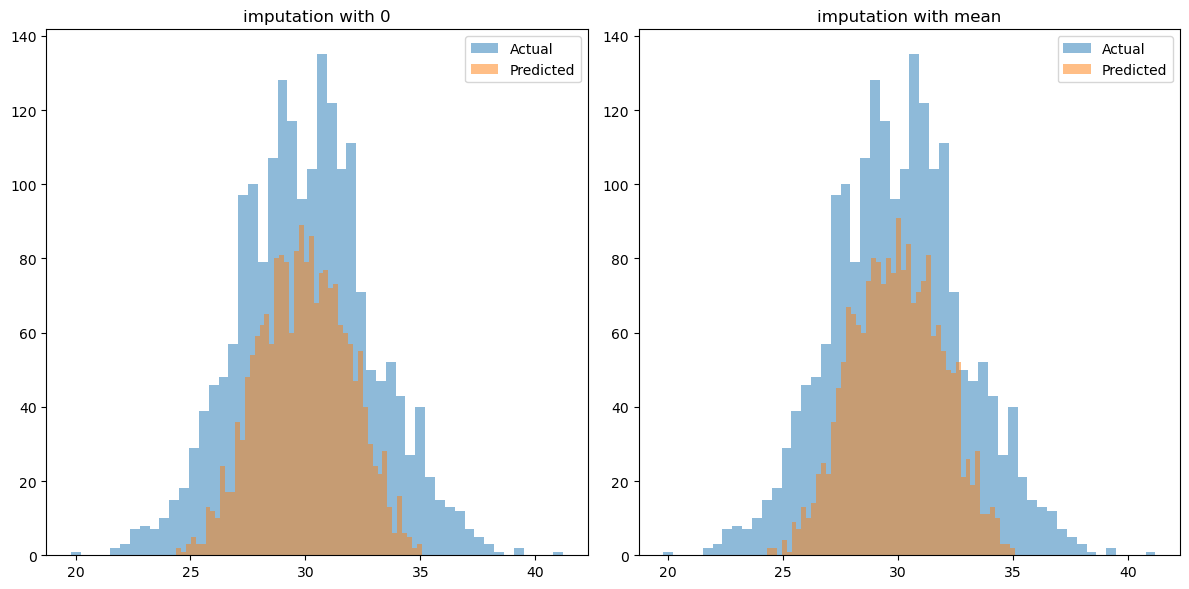

In [41]:
fig, axes = plt.subplots(1, 2, figsize = (12, 6))

# plot for 0 imputation
axes[0].hist(y_val, bins = 50, alpha = 0.5, label = "Actual")
axes[0].hist(y_pred_0, bins = 50, alpha = 0.5, label = "Predicted")
axes[0].set_title("imputation with 0")
axes[0].legend()

# plot for mean imputation
axes[1].hist(y_val, bins = 50, alpha = 0.5, label = "Actual")
axes[1].hist(y_pred_mean, bins = 50, alpha = 0.5, label = "Predicted")
axes[1].set_title("imputation with mean")
axes[1].legend()


plt.tight_layout()
plt.show()

## **linear regression with regularization**

In [42]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = linear_regression_reg(X_train_0.drop(columns = "fuel_efficiency_mpg"), y_train, r = r)

    y_pred = w0 + X_val_0.drop(columns = "fuel_efficiency_mpg").dot(w)
    score = round(rmse(y_val, y_pred), 4)
    
    print(r, w0, score)

0 -153.88496188313275 2.2053
0.01 -148.3092124420291 2.2058
0.1 -111.83871039317455 2.2241
1 -32.33186596510836 2.3492
5 -7.772852210017248 2.4094
10 -3.9871164160237242 2.4195
100 -0.40821964884753825 2.4292


In [43]:
seeds = list(range(10))
scores_q5 = []
for seed in seeds:
    df_train_s, df_val_s, df_test_s = split_data(data, seed=seed)
    y_train_s = df_train_s["fuel_efficiency_mpg"].values
    y_val_s = df_val_s["fuel_efficiency_mpg"].values

    X_train_s = prepare_X(df_train_s, "horsepower", 0)
    X_val_s = prepare_X(df_val_s, "horsepower", 0)

    w0, w = linear_regression(X_train_s.drop(columns = "fuel_efficiency_mpg"), y_train_s)
    y_pred_s = w0 + X_val_s.drop(columns = "fuel_efficiency_mpg").dot(w)
    score = rmse(y_val_s, y_pred_s)
    scores_q5.append(score)
    print(f"seed={seed} RMSE={round(score, 3)}")

std_q5 = round(np.std(scores_q5), 3)
print("Std of scores:", std_q5)

df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=0 RMSE=2.239
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=1 RMSE=2.202
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=2 RMSE=2.163
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=3 RMSE=2.204
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=4 RMSE=2.202
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=5 RMSE=2.246
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=6 RMSE=2.27
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=7 RMSE=2.191
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=8 RMSE=2.217
df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
seed=9 RMSE=2.207
Std of scores: 0.029


In [46]:
df_train_9, df_val_9, df_test_9 = split_data(data, seed=9)

df_full_train = pd.concat([df_train_9, df_val_9], ignore_index=True)
y_full_train = df_full_train['fuel_efficiency_mpg'].values
y_test_9 = df_test_9['fuel_efficiency_mpg'].values

X_full_train = df_full_train.fillna(0)
X_test_9 = df_test_9.fillna(0)

w0, w = linear_regression_reg(X_full_train.drop(columns = "fuel_efficiency_mpg"), y_full_train, r=0.001)

y_pred_test = w0 + X_test_9.drop(columns = "fuel_efficiency_mpg").dot(w)
rmse_test = round(rmse(y_test_9, y_pred_test), 3)
print("RMSE on test:", rmse_test)

df_train shape: (6000, 5)
df_val shape: (2000, 5)
df_test shape: (2000, 5)
RMSE on test: 2.236
